# 03 — 从数据到信号（Data → Signal）

**目标**：把 5 年、3 门店、4 品类的干净日销售，转化为可供预测与模拟使用的**可解释信号**。
本笔记本覆盖：总体趋势、周期检测（无监督）、周/年季节模式、门店差异、价格信号、节假日效应与无监督异常检测。


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if (Path.cwd() / 'src').exists():
    sys.path.insert(0, str(Path.cwd() / 'src'))
import helper_utils as hu

NAVY='#1b4f72'; BLUE='#2874a6'; AMBER='#e67e22'; RED='#c0392b'
GREEN='#1e8449'; GREY='#7f8c8d'
COL={'Beverages':BLUE,'Bakery':AMBER,'Meat':RED,'Produce':GREEN}
CAT=['Beverages','Bakery','Meat','Produce']
plt.rcParams.update({'figure.dpi':100,'font.size':9,'axes.spines.top':False,'axes.spines.right':False})

raw = hu.load_raw()
p = hu.build_panel()
s = hu.daily_total(p)
print('sales rows:', len(raw['sales']), '| dates:', len(raw['dates']))
print('panel shape:', p.shape)
p.head(3)


sales rows: 21912 | dates: 1826
panel shape: (21912, 26)


## 1. 总体趋势

5 年日营收，叠加 30 日移动平均（短期波动）与 365 日移动平均（长期趋势）。


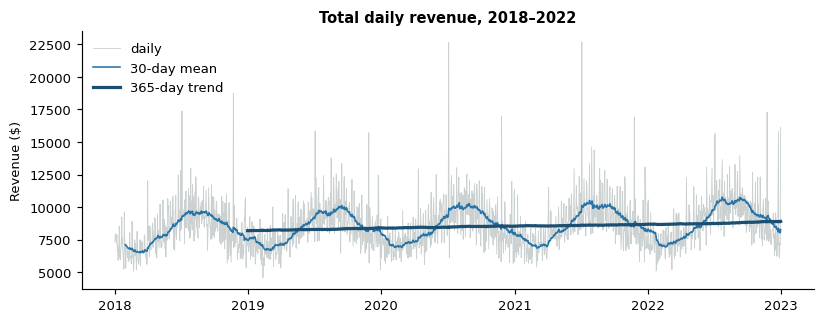

In [2]:
fig, ax = plt.subplots(figsize=(9,3.2))
ax.plot(s.index, s.values, color=GREY, alpha=0.4, lw=0.6, label='daily')
ax.plot(s.index, s.rolling(30).mean(), color=BLUE, lw=1.1, label='30-day mean')
ax.plot(s.index, s.rolling(365).mean(), color=NAVY, lw=2.2, label='365-day trend')
ax.set_title('Total daily revenue, 2018–2022')
ax.set_ylabel('Revenue ($)')
ax.legend(frameon=False, loc='upper left')


## 2. 无监督周期检测（periodogram）

对去趋势序列做 FFT 周期图，**不依赖任何日历先验**地找出主导周期。


dominant periods (days): [365.2, 7.0, 3.5, 2.3, 10.1, 28.1]


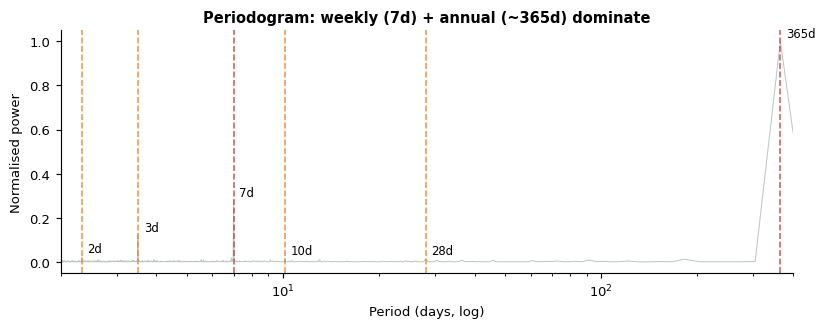

In [3]:
periods = hu.dominant_periods(s, top_n=6)
print('dominant periods (days):', [round(per,1) for per,_ in periods])

from scipy.signal import periodogram
y = hu.detrend(s).to_numpy()
f, Pxx = periodogram(y, detrend=False)
m = f > 0
fig, ax = plt.subplots(figsize=(9,3.0))
ax.plot(1/f[m], Pxx[m]/Pxx[m].max(), color=GREY, alpha=0.5, lw=0.7)
ax.set_xscale('log'); ax.set_xlim(2, 400)
for per, pw in periods[:6]:
    ax.axvline(per, color=RED if abs(per-365)<3 or abs(per-7)<1 else AMBER, ls='--', lw=1.1, alpha=0.8)
    ax.annotate(f'{per:.0f}d', (per, pw), xytext=(4,3), textcoords='offset points', fontsize=8)
ax.set_xlabel('Period (days, log)'); ax.set_ylabel('Normalised power')
ax.set_title('Periodogram: weekly (7d) + annual (~365d) dominate')


## 3. 周度与年度季节模式（按品类）

分品类看一周内的起伏与一年内的起伏，揭示「谁更季节敏感」。


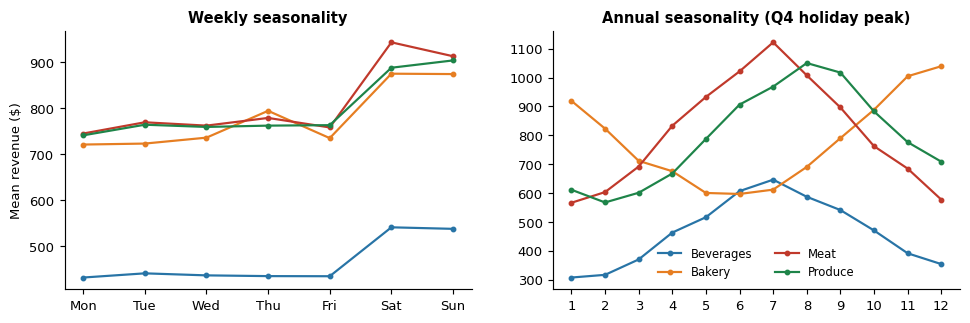

In [4]:
wp = p.groupby(['category_name','dow'])['sales_revenue'].mean().reset_index()
mp = p.groupby(['category_name','month'])['sales_revenue'].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11,3.2))
for c in CAT:
    d = wp[wp.category_name==c].sort_values('dow')
    axes[0].plot(d.dow, d.sales_revenue, marker='o', ms=3, color=COL[c], label=c)
    d2 = mp[mp.category_name==c].sort_values('month')
    axes[1].plot(d2.month, d2.sales_revenue, marker='o', ms=3, color=COL[c], label=c)
axes[0].set_xticks(range(7)); axes[0].set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
axes[0].set_title('Weekly seasonality'); axes[0].set_ylabel('Mean revenue ($)')
axes[1].set_xticks(range(1,13)); axes[1].set_title('Annual seasonality (Q4 holiday peak)')
axes[1].legend(frameon=False, ncol=2, fontsize=8)


## 4. 门店差异

三家门店（西雅图/波特兰/博伊西）同为西北—山地市场，体量不同但节奏一致。


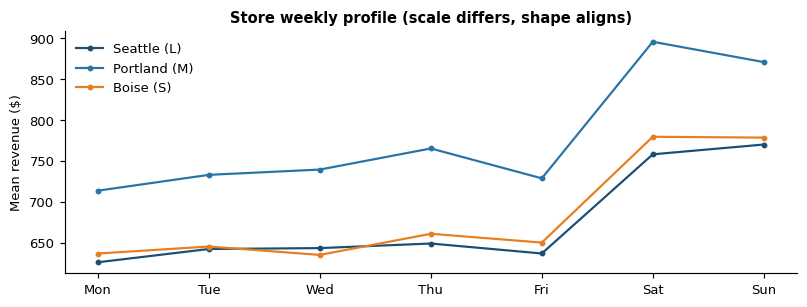

In [5]:
sp = p.groupby(['store_id','dow'])['sales_revenue'].mean().reset_index()
lab={1:'Seattle (L)',2:'Portland (M)',3:'Boise (S)'}
fig, ax = plt.subplots(figsize=(9,3.0))
for sid in [1,2,3]:
    d = sp[sp.store_id==sid].sort_values('dow')
    ax.plot(d.dow, d.sales_revenue, marker='o', ms=3, color=[NAVY,BLUE,AMBER][sid-1], label=lab[sid])
ax.set_xticks(range(7)); ax.set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
ax.set_title('Store weekly profile (scale differs, shape aligns)')
ax.set_ylabel('Mean revenue ($)'); ax.legend(frameon=False)


## 5. 价格信号

`unit_price = sales_revenue / sales_qty`。观察价格趋势，并量化「价格-数量」弹性。


  price-elasticity corr (Beverages): +0.007
  price-elasticity corr (Bakery): -0.014
  price-elasticity corr (Meat): +0.020
  price-elasticity corr (Produce): -0.006


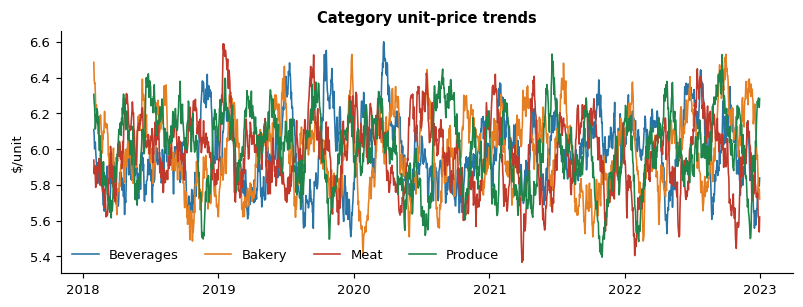

In [6]:
qp = p.groupby(['date','category_name'])['unit_price'].mean().reset_index()
fig, ax = plt.subplots(figsize=(9,3.0))
for c in CAT:
    d = qp[qp.category_name==c]
    ax.plot(d.date, d.unit_price.rolling(30).mean(), lw=1.1, color=COL[c], label=c)
ax.set_title('Category unit-price trends'); ax.set_ylabel('$/unit'); ax.legend(frameon=False, ncol=4)

for c in CAT:
    dd = p[p.category_name==c]
    r = np.corrcoef(np.log(dd.sales_qty+1), np.log(dd.unit_price))[0,1]
    print(f'  price-elasticity corr ({c}): {r:+.3f}')


## 6. 节假日效应 + 无监督异常检测

用 STL 残差的 |z|>3.5 做**无监督**异常检测，再与节假日日历交叉验证。


holiday uplift: +12.5%  (holiday mean 9577 vs non-holiday 8513)
detected anomalies: 18, on holidays: 12 (precision 66.67%)


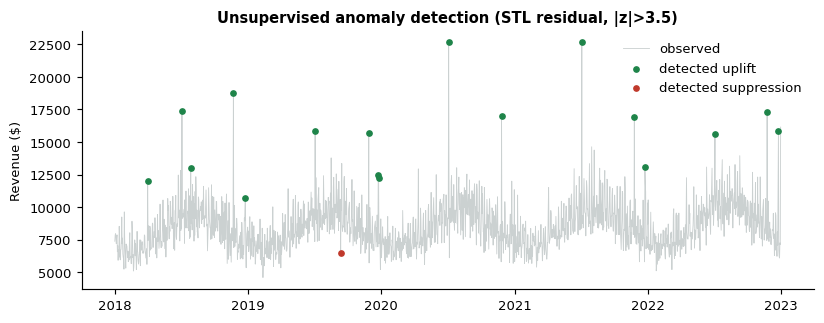

In [7]:
hol = hu.us_holiday_calendar(2018, 2022)
day = s.loc[hol['date'].tolist()]
non = s.loc[~s.index.isin(hol['date'])]
uplift = 100*(day.mean()/non.mean()-1)
print(f'holiday uplift: +{uplift:.1f}%  (holiday mean {day.mean():.0f} vs non-holiday {non.mean():.0f})')

an = hu.detect_anomalies(s, period=7, k=3.5)
an = an.merge(hol.assign(is_holiday=1), on='date', how='left')
n_det = int(an['is_anomaly'].sum())
n_hit = int(an.loc[an['is_anomaly'],'is_holiday'].fillna(0).sum())
print(f'detected anomalies: {n_det}, on holidays: {n_hit} (precision {n_hit/max(n_det,1):.2%})')

fig, ax = plt.subplots(figsize=(9,3.2))
ax.plot(s.index, s.values, color=GREY, alpha=0.4, lw=0.6, label='observed')
up = an[an.direction=='uplift']; dn = an[an.direction=='suppression']
ax.scatter(up.date, up.observed, color=GREEN, s=13, label='detected uplift', zorder=3)
ax.scatter(dn.date, dn.observed, color=RED, s=13, label='detected suppression', zorder=3)
ax.set_title('Unsupervised anomaly detection (STL residual, |z|>3.5)')
ax.set_ylabel('Revenue ($)'); ax.legend(frameon=False)


## 7. 小结（信号结论）

- 主导周期 **7 天（周）** + **~365 天（年）**，由无监督周期图自动发现；
- 周末抬升、Q4 节假日峰值是年周期主因；节假日当日销售平均 **+12.5%**；
- **价格近乎无弹性**（相关系数≈0）：需求由日历/节假日驱动，而非价格；
- 无监督异常检测 18 个异常点中 12 个落在节假日上（精确率 66.7%）。
